In [3]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from nilearn import plotting
import random
import numpy as np
import json 
import matplotlib as mpl

from src.config import OUT_PATH, FREQ_BAND, COL_REG
from src.setting import ExcludSubj, GetInfo
from src.preproc import TFRmEvents, BbEvents

tfr_path = OUT_PATH+ '/Data_longWOBS_mf70-160'
subj_included = [file.replace('_TFRtrials.p', '') for file in os.listdir(tfr_path) if file[-len('TFRtrials.p'):] == 'TFRtrials.p']
subj_included = ExcludSubj(subj_included, data_path=tfr_path)

coord, areas, elect_list, subj_list, regions = GetInfo(subj_included, data_path=tfr_path)
print(f"Subject Nbr is {len(subj_included)}")

info_file = tfr_path + f'/{subj_included[0]}_info.json'
with open(info_file) as f:
    info = json.load(f)
    time_epoch = info['time_epoch']
    time= info['time_tfr']

plt.style.use('seaborn-v0_8-dark')

colors = plt.get_cmap('tab10')
element_colors = {elem: colors((i+3)**3 + 50) for i, elem in enumerate(FREQ_BAND)}

Subject Nbr is 30


## Raw

In [4]:
epoch_path = OUT_PATH  + '/Data_longWOBS'
data = []
for subj in subj_included:
    data_mean = BbEvents(subj, data_path=epoch_path)
    info_file = f'{epoch_path}/{subj}_info.json'
    data.append(data_mean)
    
data_grp = np.hstack(data)
data_grp_mean = data_grp.mean(0)

Text(0.5, 1.05, 'Raw data per Regions of interest')

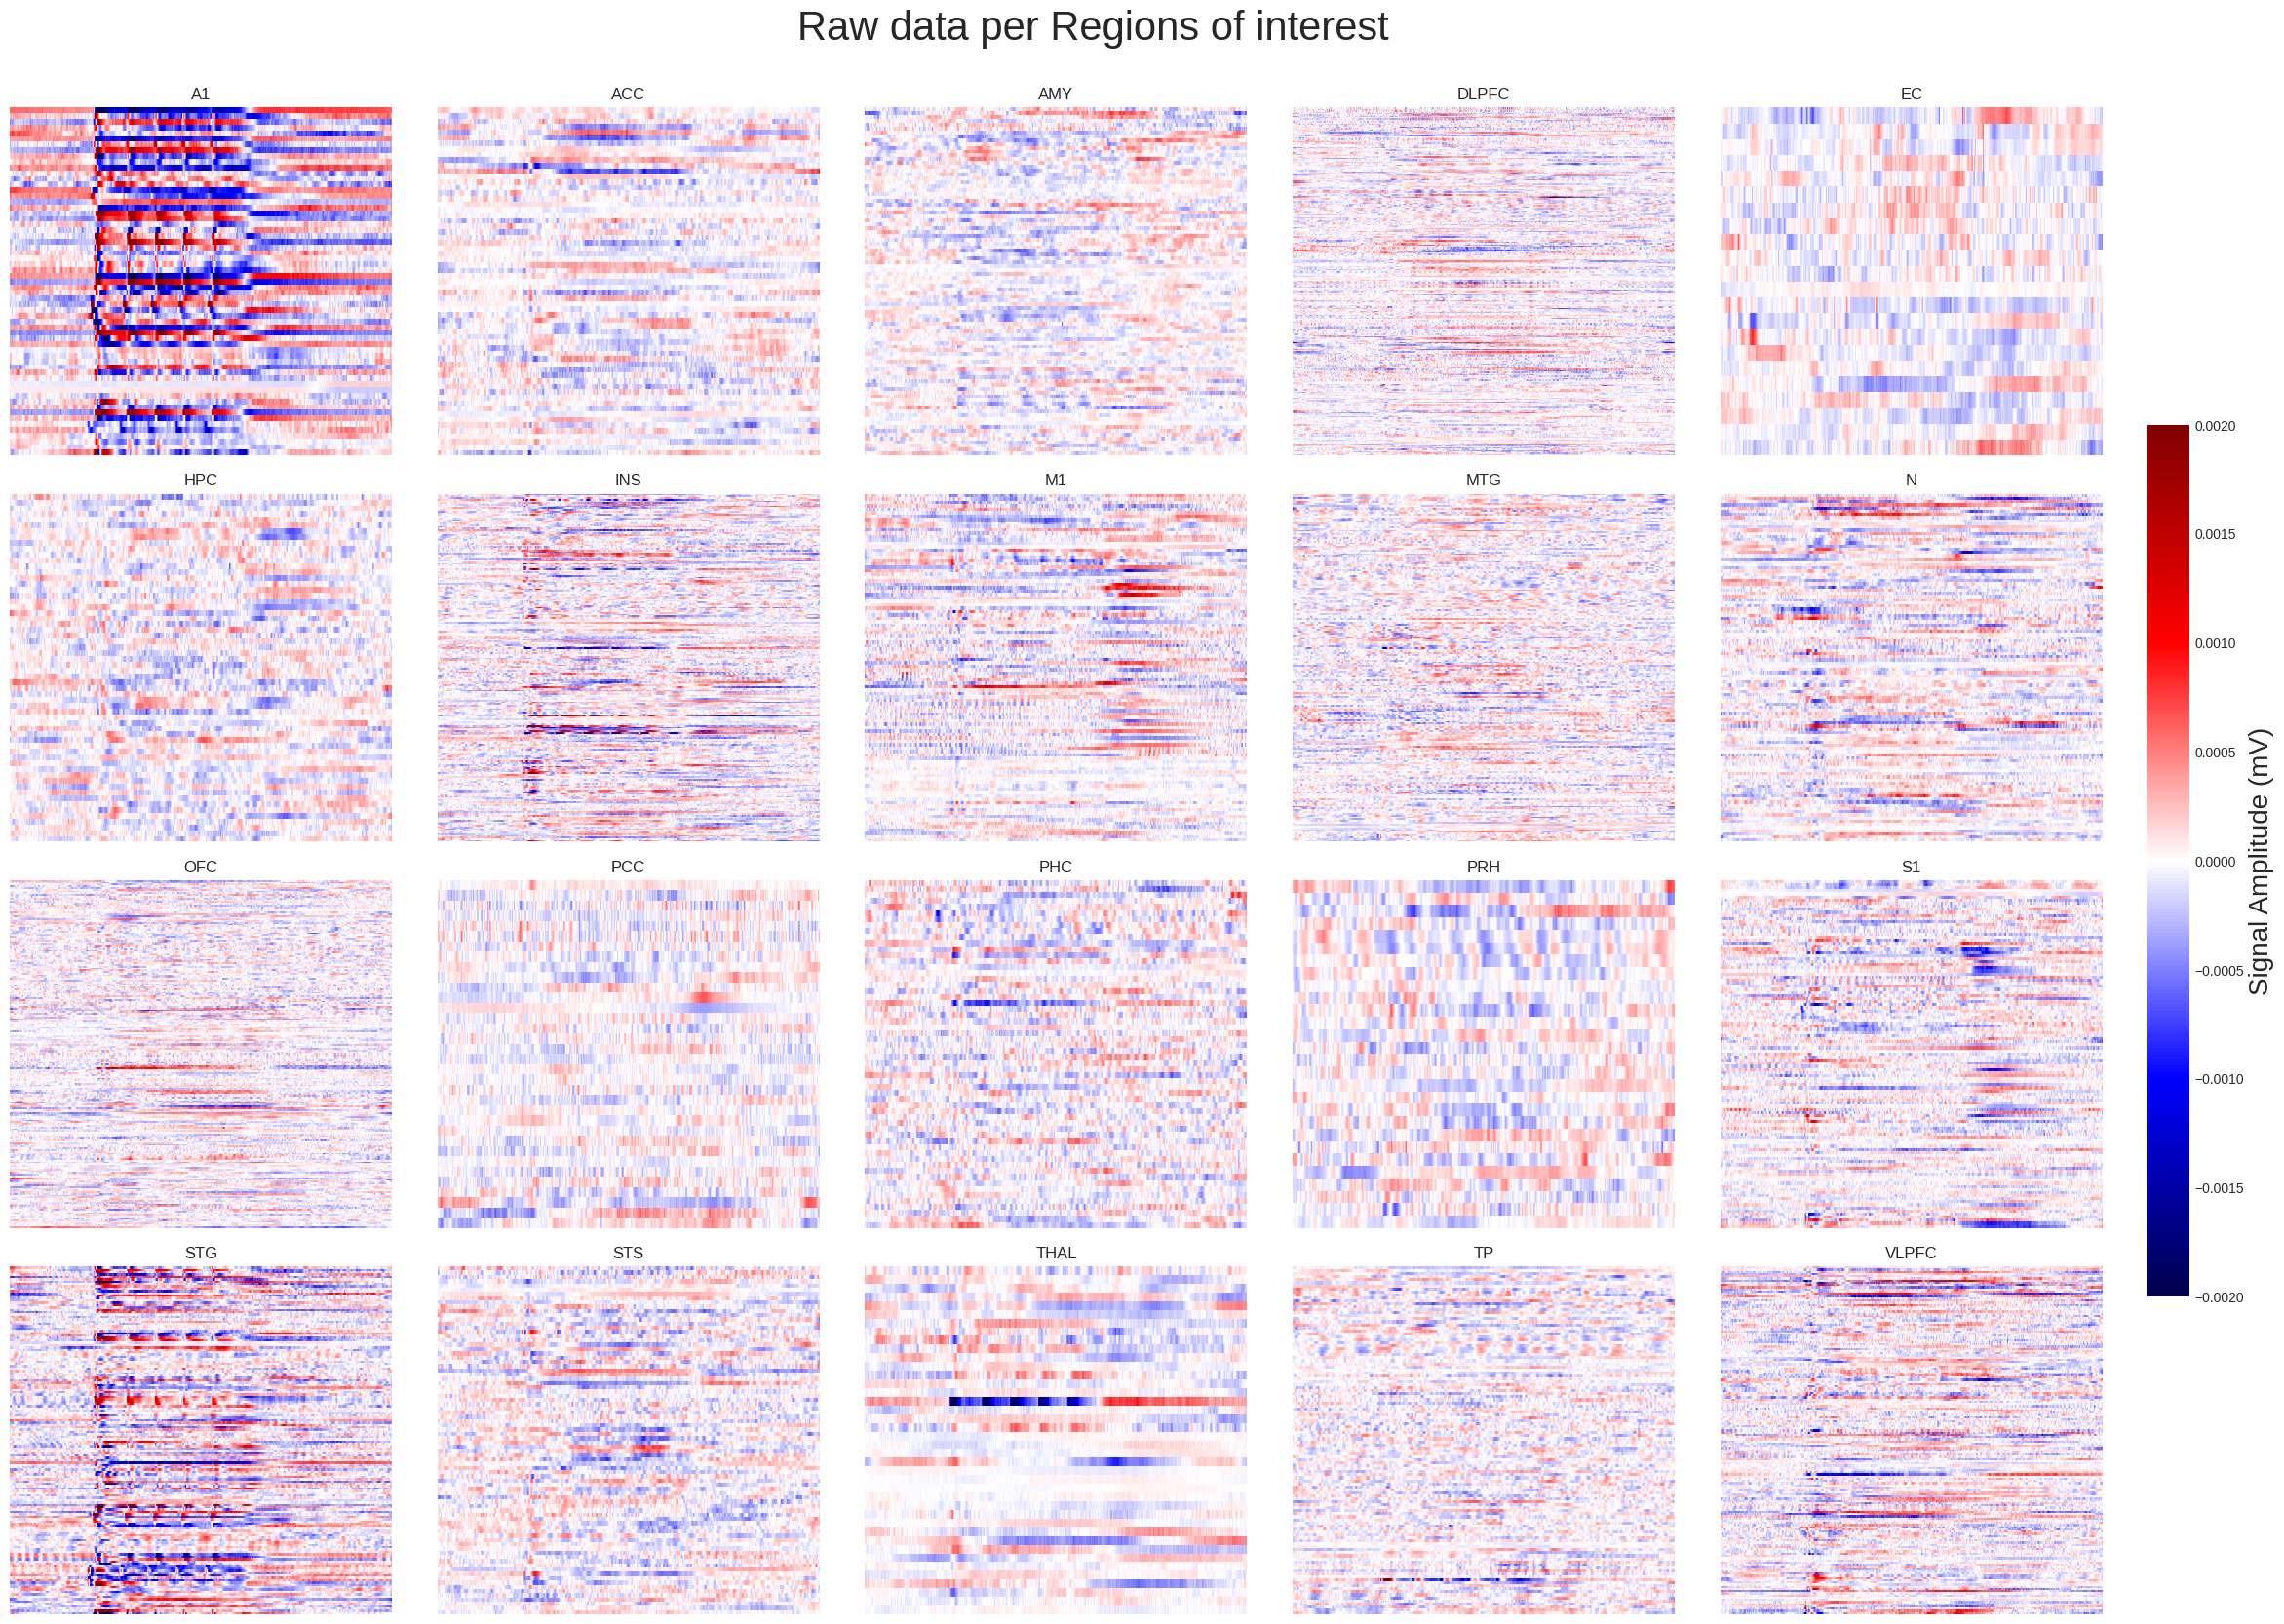

In [5]:
df_1 = pd.DataFrame(data_grp.mean(axis=0))
vmax  = 0.002
vmin = -0.002
df_1['region']= regions
df_1['region'] = df_1['region'].fillna('NON')

unique_r = np.unique(df_1['region'])
fig, axs = plt.subplots(4, int(len(unique_r)/4), figsize = (len(unique_r),16))
fig.tight_layout()
for ax, r in zip(axs.flatten(),unique_r) :
    sns.heatmap(df_1.query('region == @r').drop(columns = 'region'), ax= ax, xticklabels=False, yticklabels=False, center = 0, cmap = 'seismic', vmax=vmax, vmin=vmin, cbar=False)
    ax.set_title(r)

norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)

sm = mpl.cm.ScalarMappable(norm=norm, cmap='seismic')
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axs,
    orientation='vertical',
    fraction=0.02,
    pad=0.02
)

cbar.set_label('Signal Amplitude (mV)', size=20) 

fig.suptitle('Raw data per Regions of interest', y=1.05, size= 30)
#fig.savefig(OUT_PATH+'/figues/raw_regions.png', bbox_inches = 'tight', pad_inches=0.4)

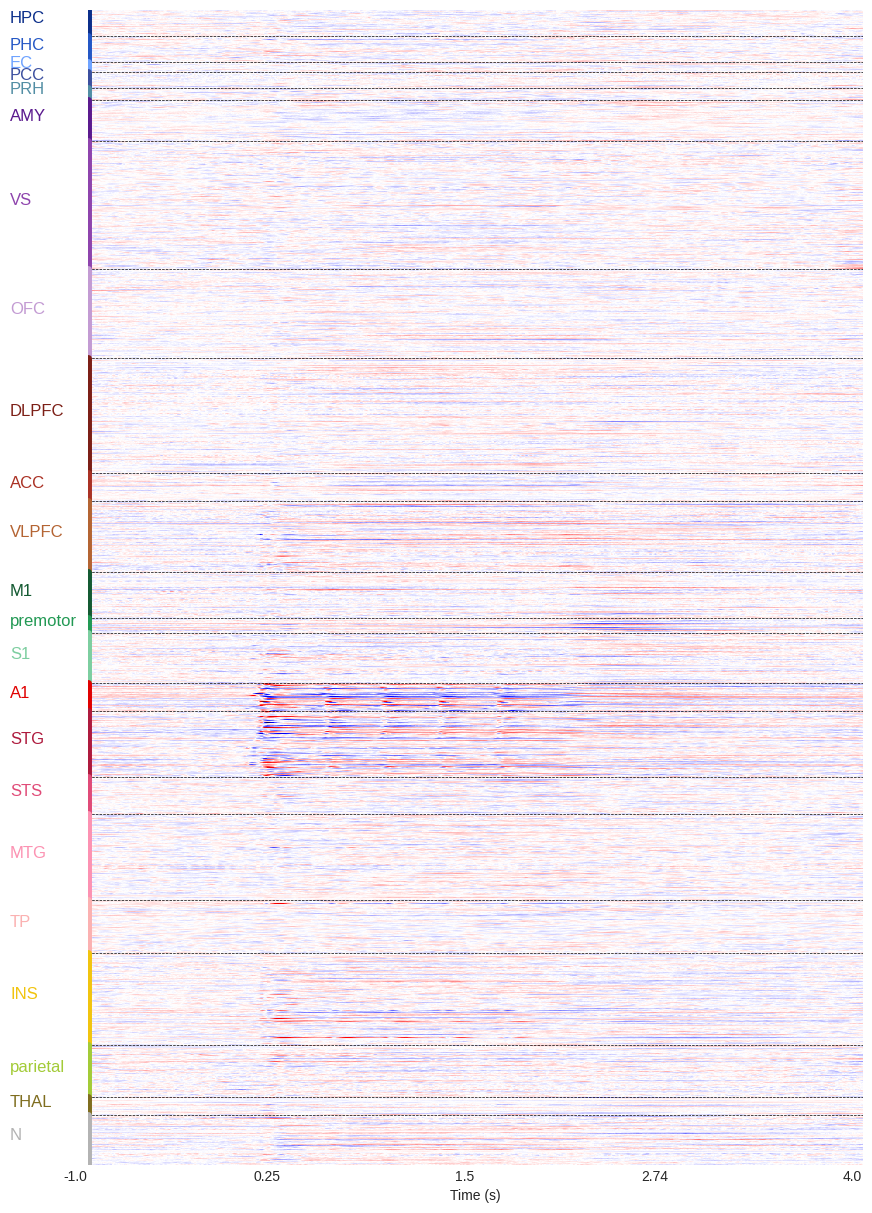

In [6]:
fig, ax =plt.subplots(figsize = (10, 15))
regions_count = df_1.groupby('region').count().loc[:, 0].reindex(COL_REG.keys()).values
regions_sorted = list(COL_REG.keys())
dict_region = {r:i for i, r in enumerate(regions_sorted)}

sns.heatmap(df_1.sort_values(by=['region'],key=lambda x: x.map(dict_region)).drop(columns=['region']), ax = ax, xticklabels=False, yticklabels=False, center = 0, cmap = 'seismic', cbar=False)

y_start = 0
for i, r in enumerate(regions_sorted) : 
    ax.text(x=-100, y= y_start + regions_count[i]/2, s=regions_sorted[i], c=COL_REG[r], size ='large')
    ax.plot([0, 0], [y_start, y_start + regions_count[i]], linewidth=5, c=COL_REG[r])
    y_start += regions_count[i]
    ax.hlines(y=y_start,xmin=0,xmax=df_1.shape[1] - 1,colors='black',linestyles='dashed',linewidth=0.5)

time_values = time_epoch

n_cols = len(time_values)
n_display = 5
tick_idx = np.linspace(0, n_cols - 1, n_display, dtype=int)
ax.set_xticks(tick_idx)
ax.set_xticklabels(
    np.round(np.array(time_values)[tick_idx], 2),
    ha='right'
)

ax.set_xlabel("Time (s)")
plt.show()

Text(0.5, 1.05, 'Raw data per Subject')

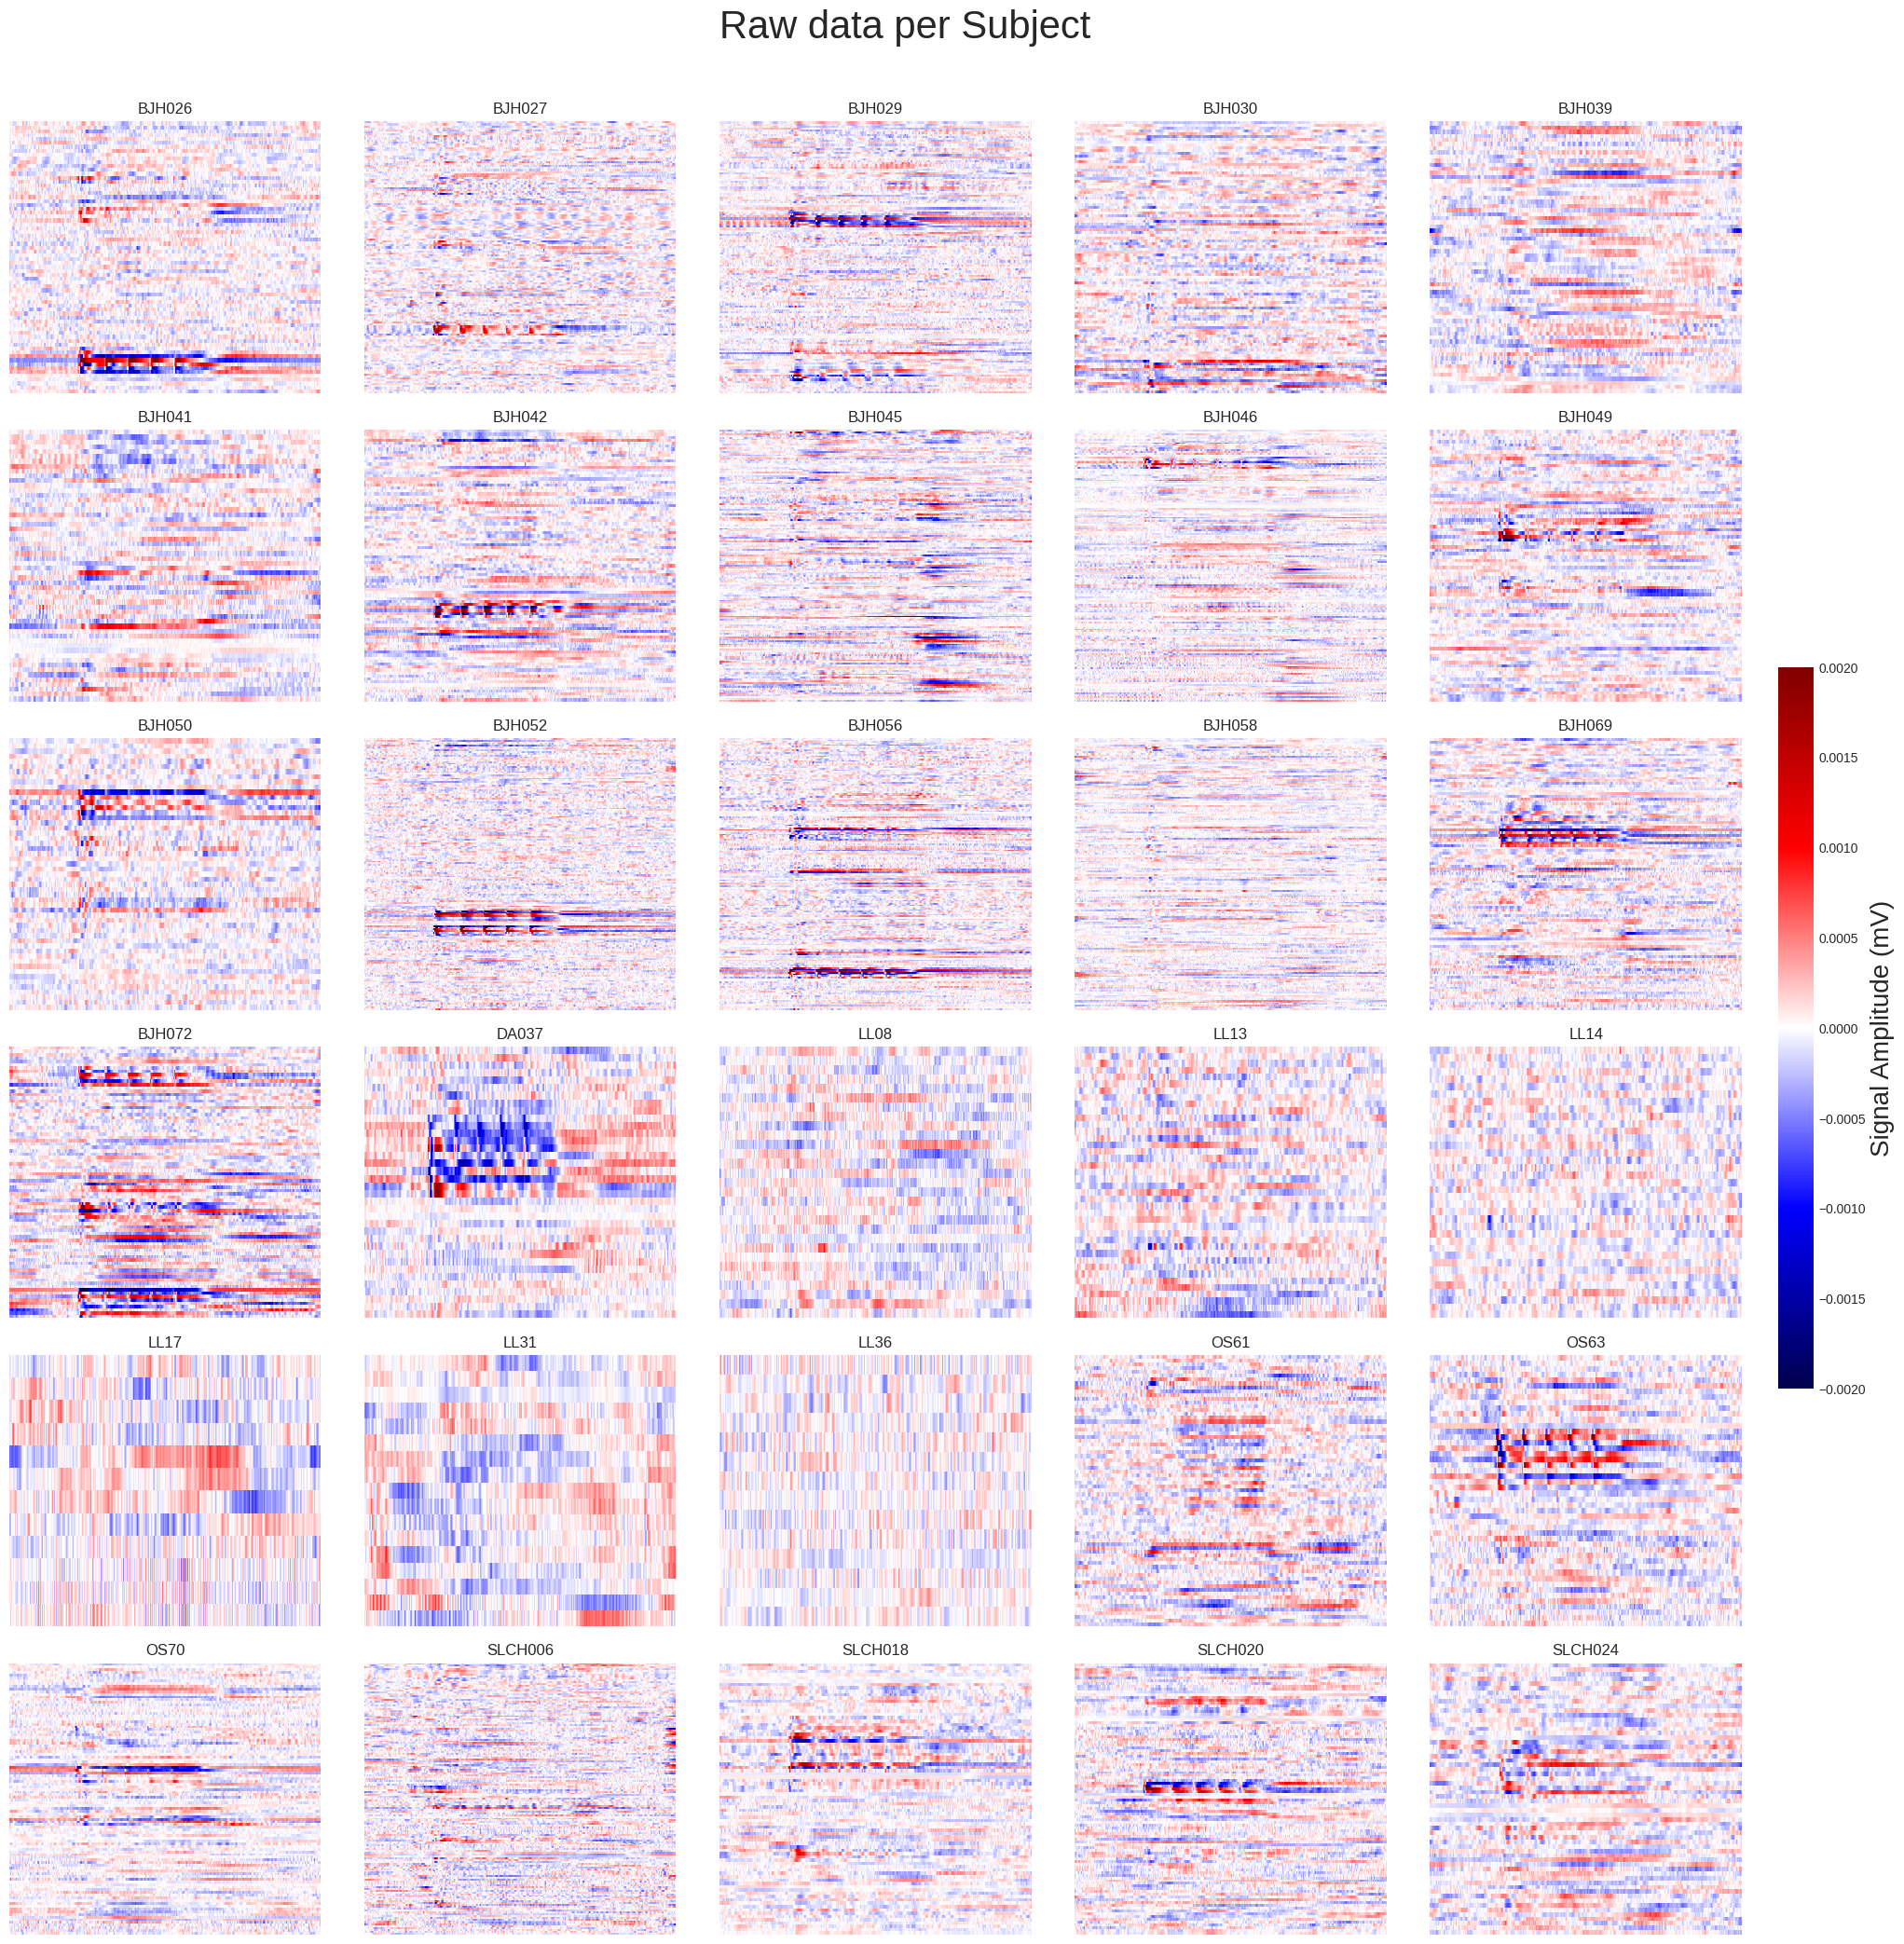

In [7]:
df_1['subj'] = subj_list
unique_r = np.unique(df_1['subj'])
fig, axs = plt.subplots(int(len(unique_r)/5),5, figsize = (20,20))
fig.tight_layout()
for ax, r in zip(axs.flatten(),unique_r) :
    sns.heatmap(df_1.query('subj == @r').drop(columns = ['subj', 'region']), ax= ax, xticklabels=False, yticklabels=False, center = 0, cmap = 'seismic', vmax=vmax, vmin=vmin, cbar=False)
    ax.set_title(r)

import matplotlib as mpl
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='seismic')
sm.set_array([])
cbar = fig.colorbar(
    sm,
    ax=axs,
    orientation='vertical',
    fraction=0.02,
    pad=0.02
)

cbar.set_label('Signal Amplitude (mV)', size=20)
fig.suptitle('Raw data per Subject', y=1.05, size= 30)

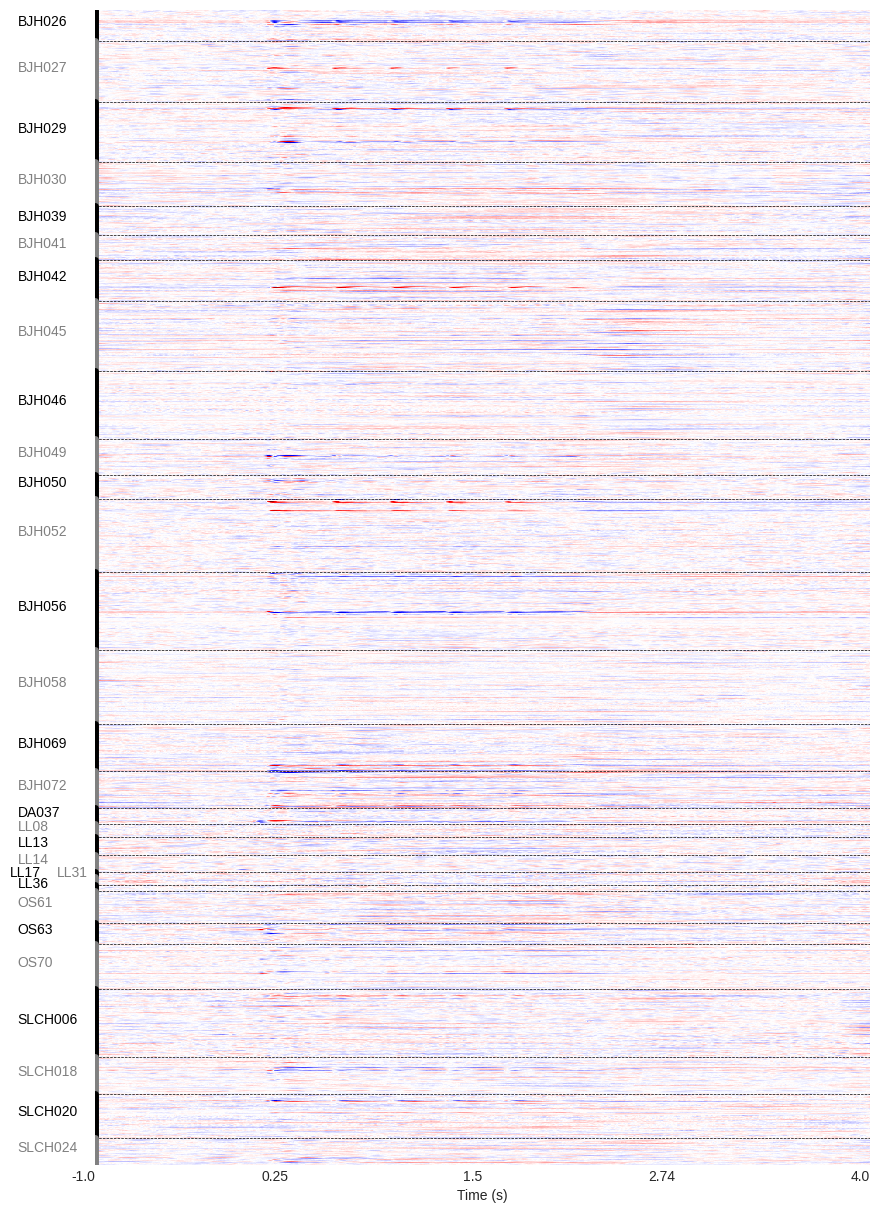

In [9]:
fig, ax =plt.subplots(figsize = (10, 15))
subj_sorted, subj_count = np.unique(df_1.sort_values('subj').subj, return_counts=True)
#subj_sorted = subj_sorted[:10]
#subj_count = subj_count[:10]
cmap1 = plt.get_cmap('tab20')
cmap2 = plt.get_cmap('Set1')
df_1_subset = df_1 #.query('subj in @subj_sorted')
num_colors_needed = len(subj_sorted)
colors1 = [cmap1(i) for i in range(20)]
colors2 = [cmap2(i) for i in range(num_colors_needed - len(colors1))]
all_colors = colors1 + colors2

colors_s = {elem: all_colors[i] for i, elem in enumerate(subj_sorted)}

pattern = ['black', 'grey']
colors_list = [pattern[i % len(pattern)] for i in range(len(subj_sorted))]
colors_s = {elem: colors_list[i] for i, elem in enumerate(subj_sorted)}

sns.heatmap(df_1_subset.sort_values('subj').drop(columns = ['region','subj']), ax = ax, xticklabels=False, yticklabels=False, center = 0, cmap = 'seismic', cbar=False) 

y_start = 0
i = 0

while i < len(subj_sorted):

    r = subj_sorted[i]
    y_center = y_start + subj_count[i] / 2

    # ---- Special case: LL17 & LL31 ----
    if r in ["LL17", "LL31"]:

        # Compute combined block height
        total_height = subj_count[i] + subj_count[i+1]
        y_center_shared = y_start + total_height / 2

        # Print both at same y, slightly shifted in x
        ax.text(x=-70, y=y_center_shared-3, s="LL17",
                c=colors_s["LL17"], ha='right')

        ax.text(x=-10, y=y_center_shared-3, s="LL31",
                c=colors_s["LL31"], ha='right')

        # Draw their color bars separately (optional: keep individual bars)
        ax.plot([0, 0], [y_start, y_start + subj_count[i]],
                linewidth=5, c=colors_s["LL17"])

        ax.plot([0, 0],
                [y_start + subj_count[i],
                 y_start + total_height],
                linewidth=5, c=colors_s["LL31"])

        y_start += total_height
        i += 2  # skip next since already handled

    else:
        ax.text(x=-100, y=y_center,
                s=r,
                c=colors_s[r], 
                fontsize=10)

        ax.plot([0, 0],
                [y_start, y_start + subj_count[i]],
                linewidth=5,
                c=colors_s[r])

        y_start += subj_count[i]
        i += 1

    # Region separator
    ax.hlines(
        y=y_start,
        xmin=0,
        xmax=df_1_subset.shape[1] - 1,
        colors='black',
        linestyles='dashed',
        linewidth=0.5
    )

time_values = time_epoch

n_cols = len(time_values)
n_display = 5
tick_idx = np.linspace(0, n_cols - 1, n_display, dtype=int)
ax.set_xticks(tick_idx)
ax.set_xticklabels(
    np.round(np.array(time_values)[tick_idx], 2),
    ha='right'
)

ax.set_xlabel("Time (s)")
plt.show()

/tmp/ipykernel_23961/3173158396.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)


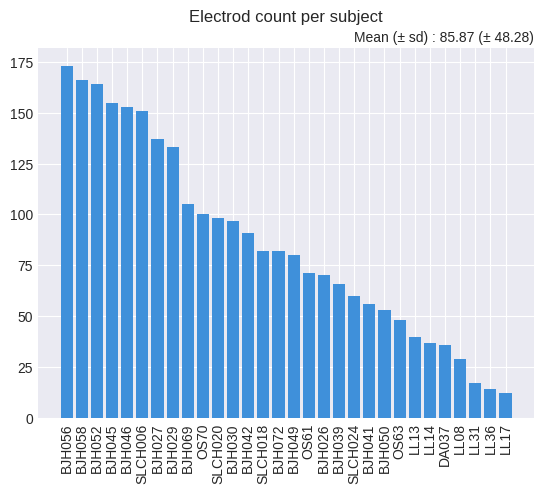

/tmp/ipykernel_23961/3173158396.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation = 90, fontsize=17)
/tmp/ipykernel_23961/3173158396.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=17)


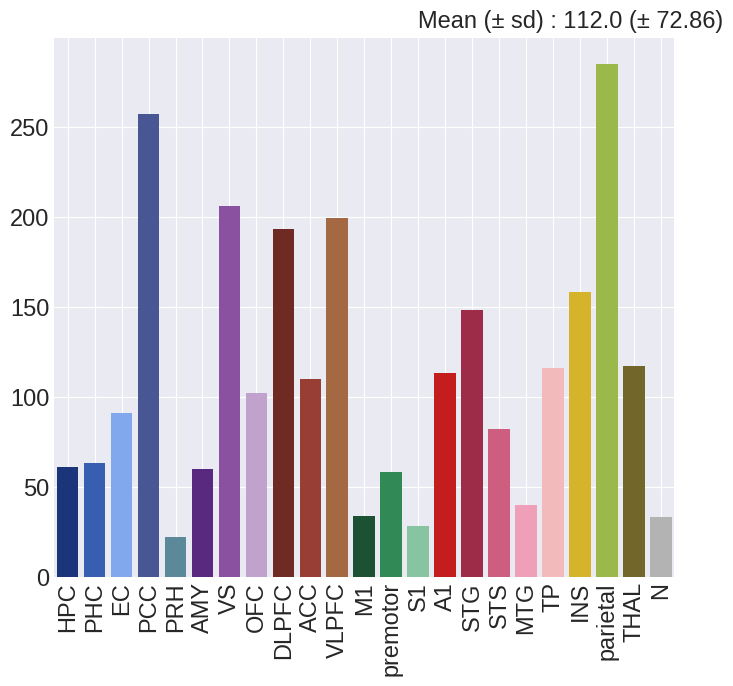

In [20]:
labs, counts = np.unique(subj_list, return_counts=True)
order = np.argsort(counts)[::-1]
fig, ax= plt.subplots()
ax.bar(labs[order], counts[order])
ax.set_xticklabels(ax.get_xticklabels(), rotation = 90)
mean = np.round(np.mean(counts), 2)
std = np.round(np.std(counts), 2)
ax.grid()
ax.set_title(f'Electrod count per subject', y=1.05)
ax.text(x= 19, y=185, s=f'Mean (± sd) : {mean} (± {std})')
plt.show()

labs, counts = np.unique(df_1['region'].values, return_counts=True)
order = np.argsort(counts)[::-1]

fig, ax= plt.subplots(figsize=(8, 7))
df =df_1.groupby('region').count().loc[:, 0].reindex(COL_REG.keys()).reset_index()
labs = df['region'].values
count=df[0].values
sns.barplot(x=labs, y=counts, hue =labs,palette=COL_REG, ax=ax)
ax.set_xticklabels(ax.get_xticklabels(), rotation = 90, fontsize=17)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=17)
mean = np.round(np.mean(counts), 2)
std = np.round(np.std(counts), 2)
ax.grid()
#ax.set_title(f'Electrode count per ROIs', y=1.05)
ax.text(x= 13, y=305, s=f'Mean (± sd) : {mean} (± {std})', fontsize=17)
plt.show()

## PRES DATA INTRO

In [8]:
df= pd.DataFrame()
df.loc[:,['x', 'y', 'z']] = coord
df.loc[:, 'region'] = regions

df['region'] = df['region'].fillna('NON')
df= df.sort_values(by=['region'],key=lambda x: x.map(dict_region))
df['subj'] = subj_list
mapper = {reg:num for num, reg in zip(np.arange(np.unique(df['region'].values).shape[0]), COL_REG.keys())}
df.loc[:, 'region_code'] = df.loc[:, 'region'].map(mapper)
mapper = {subj:num for num, subj in zip(np.arange(np.unique(df['subj'].values).shape[0]), np.unique(df['subj'].values))}
df.loc[:, 'subj_code'] = df.loc[:, 'subj'].map(mapper)
count_region = df['region'].value_counts()

for r in np.unique(df.region) :
    df.loc[df[df['region'] == r].index, 'count_region'] = count_region[r]

# ADJUSTE THE COORDS TODO
for i, row in df.iterrows() : 
    if abs(row.x) > 100 :
        df.loc[i, ['x', 'y', 'z']] =  df.loc[i, ['x', 'y', 'z']]/1000

In [9]:
# Count per area
df_count_region = pd.DataFrame(df['region'].value_counts())
for i, row in df_count_region.iterrows() :
    df_count_region.loc[i, ['x', 'y', 'z']] = df.loc[df[df['region'] == i].index, ['x', 'y', 'z']].median()
    df_count_region.loc[i, 'region_code'] = df.loc[df[df['region'] == i].index[0], 'region_code']

df_count_region = df_count_region.reindex(COL_REG.keys()).reset_index()

In [10]:
from matplotlib.colors import ListedColormap

In [11]:
coord_1 = df_count_region[['x', 'y', 'z']].values
cmap = ListedColormap(COL_REG.values())
df_count_region['index_norm'] = (df_count_region['region_code'] - df_count_region['region_code'].min())/(df_count_region['region_code'].max() - df_count_region['region_code'].min()) 
colors_1 = np.array([cmap(code) for code in df_count_region['index_norm']])
marker_size_1 =df_count_region['count']
labels_1 = [area + ' ' + str(c) for area, c in zip(list(df_count_region['region'].values), df_count_region['count'])]

coord_2 = df[['x', 'y', 'z']].values
cmap = ListedColormap(COL_REG.values())
df['index_norm'] = (df['region_code'] - df['region_code'].min())/(df['region_code'].max() - df['region_code'].min()) 
colors_2 = np.array([cmap(code) for code in df['index_norm']])
marker_size_2 = [10]*len(colors_2)
labels_2 = ['']*len(colors_2)

coord = np.concat([coord_1, coord_2])
colors = np.concat([colors_1, colors_2])
marker_size= np.concat([marker_size_1, marker_size_2])
labels = labels_1 + labels_2

In [12]:
view = plotting.view_markers(coord,marker_color=colors,marker_size=marker_size,title=f'Channels per region',title_fontsize=25, marker_labels=labels)
view.open_in_browser()
view = plotting.view_markers(coord_1,marker_color=colors_1,marker_size=marker_size_1,title=f'Channels per region',title_fontsize=25, marker_labels=labels_1)
view.open_in_browser()


In [13]:
view = plotting.view_markers(coord_2,marker_color=colors_2,marker_size=5, title=f'Channels per region',title_fontsize=25, marker_labels=labels_2)
view.open_in_browser()

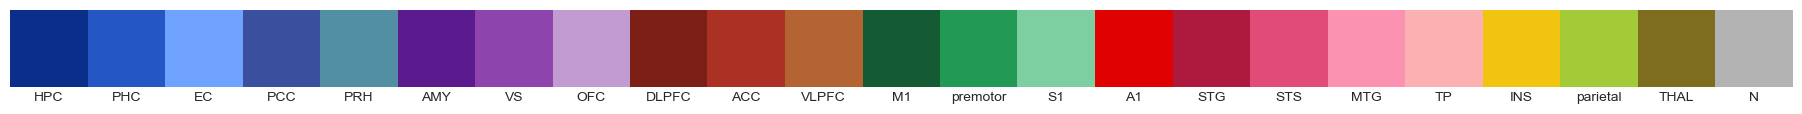

In [14]:
import matplotlib as mpl
import numpy as np

cmap = mpl.colors.ListedColormap(COL_REG.values())
bounds = np.arange(len(labels_1) + 1)
norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(len(labels_1), 1))

# Create colorbar as a legend
cb = mpl.colorbar.ColorbarBase(
    ax, cmap=cmap, norm=norm, boundaries=bounds,
    ticks=(bounds[:-1] + bounds[1:]) / 2,    # center ticks
    orientation='horizontal'
)

cb.ax.set_xticklabels(COL_REG.keys())
plt.show()


In [15]:
coord = df[['x', 'y', 'z']].values
cmap = plt.get_cmap('tab20')
colors = np.array([cmap(code) for code in df['index_norm']])
view = plotting.view_markers(coord,marker_color=colors,marker_size=5,title=f'Channels per region',title_fontsize=25)
view.open_in_browser()

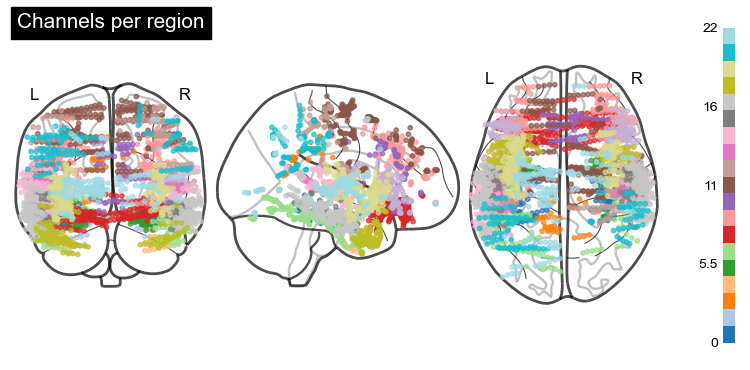

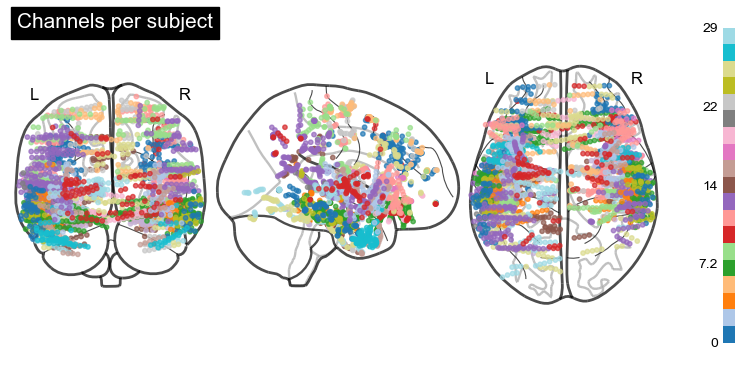

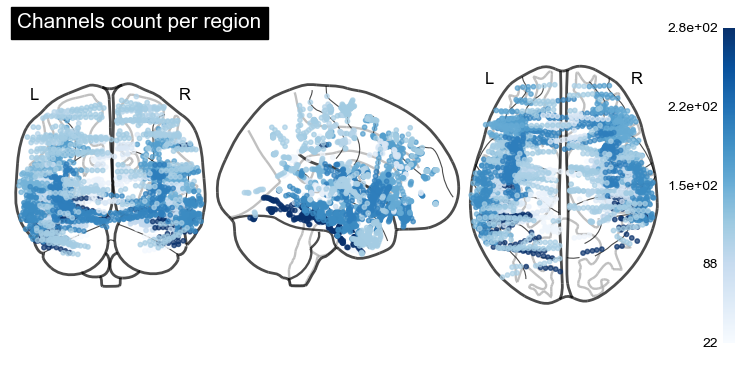

In [16]:
fig0 = plotting.plot_markers(node_coords = df[['x', 'y','z']].values,  node_size=10, node_values=df['region_code'], title=f'Channels per region',node_cmap='tab20',display_mode='ortho') #, node_vmin = -1, node_vmax = 1)
fig0 = plotting.plot_markers(node_coords = df[['x', 'y','z']].values,  node_size=10, node_values=df['subj_code'], title=f'Channels per subject',node_cmap='tab20',display_mode='ortho') #, node_vmin = -1, node_vmax = 1)
fig0 = plotting.plot_markers(node_coords = df[['x', 'y','z']].values,  node_size=10, node_values=df['count_region'], title=f'Channels count per region',node_cmap='Blues',display_mode='ortho') #, node_vmin = -1, node_vmax = 1)

In [43]:
# FREQ plot 
tfr = []
bb = []
from utils import BbEvents
for subj in subj_included :
    tfr.append(TFRmEvents(subj, data_path = tfr_path))
    bb.append(BbEvents(subj, data_path = tfr_path))
TFRm =np.concatenate(tfr, axis = 1)
BB = np.concatenate(bb, axis=1)

ValueError: zero-size array to reduction operation fmin which has no identity

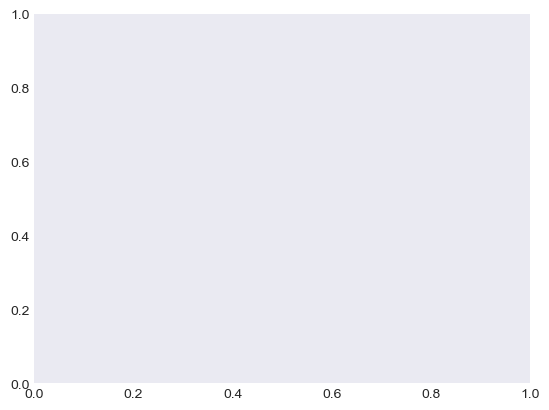

In [38]:
BB.shape
id_r = df[df['region'] == r ].index
BB_r = BB[0, id_r, :]

fig, ax = plt.subplots()
sns.heatmap(BB_r, cmap = 'seismic', xticklabels=False, yticklabels=False, ax= ax, center=0)
ax.set_xlabel('Time')
ax.set_ylabel('Channels (A1)')

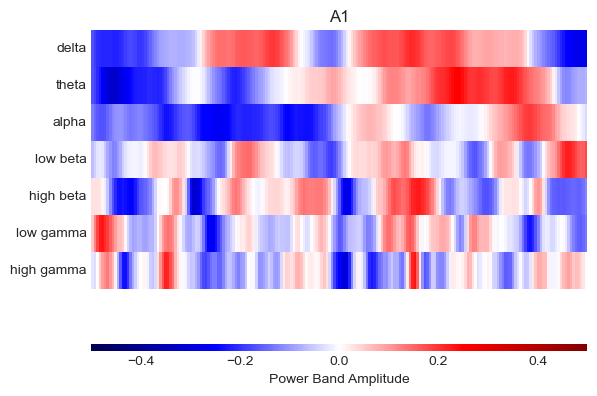

In [40]:
hm_list = []
from utils import FREQ_BAND
fig, ax= plt.subplots()

for r in np.unique(['A1']) : #['A1']
    id_r = df[df['region'] == r ].index
    tfrm_r = TFRm[0, id_r, :, :].mean(axis=0)
    hm = sns.heatmap(tfrm_r, ax=ax,cbar=False, cmap = 'seismic', vmin = -0.5, vmax = 0.5, xticklabels=False)
    hm_list.append(hm)
    ax.set_title(r)
    ax.grid()
    ax.set_yticklabels([f.replace('_', ' ') for f in FREQ_BAND], rotation = 0)

cbar = fig.colorbar(hm_list[-1].collections[-1], ax=ax, orientation='horizontal',  aspect=70)
cbar.set_label("Power Band Amplitude")

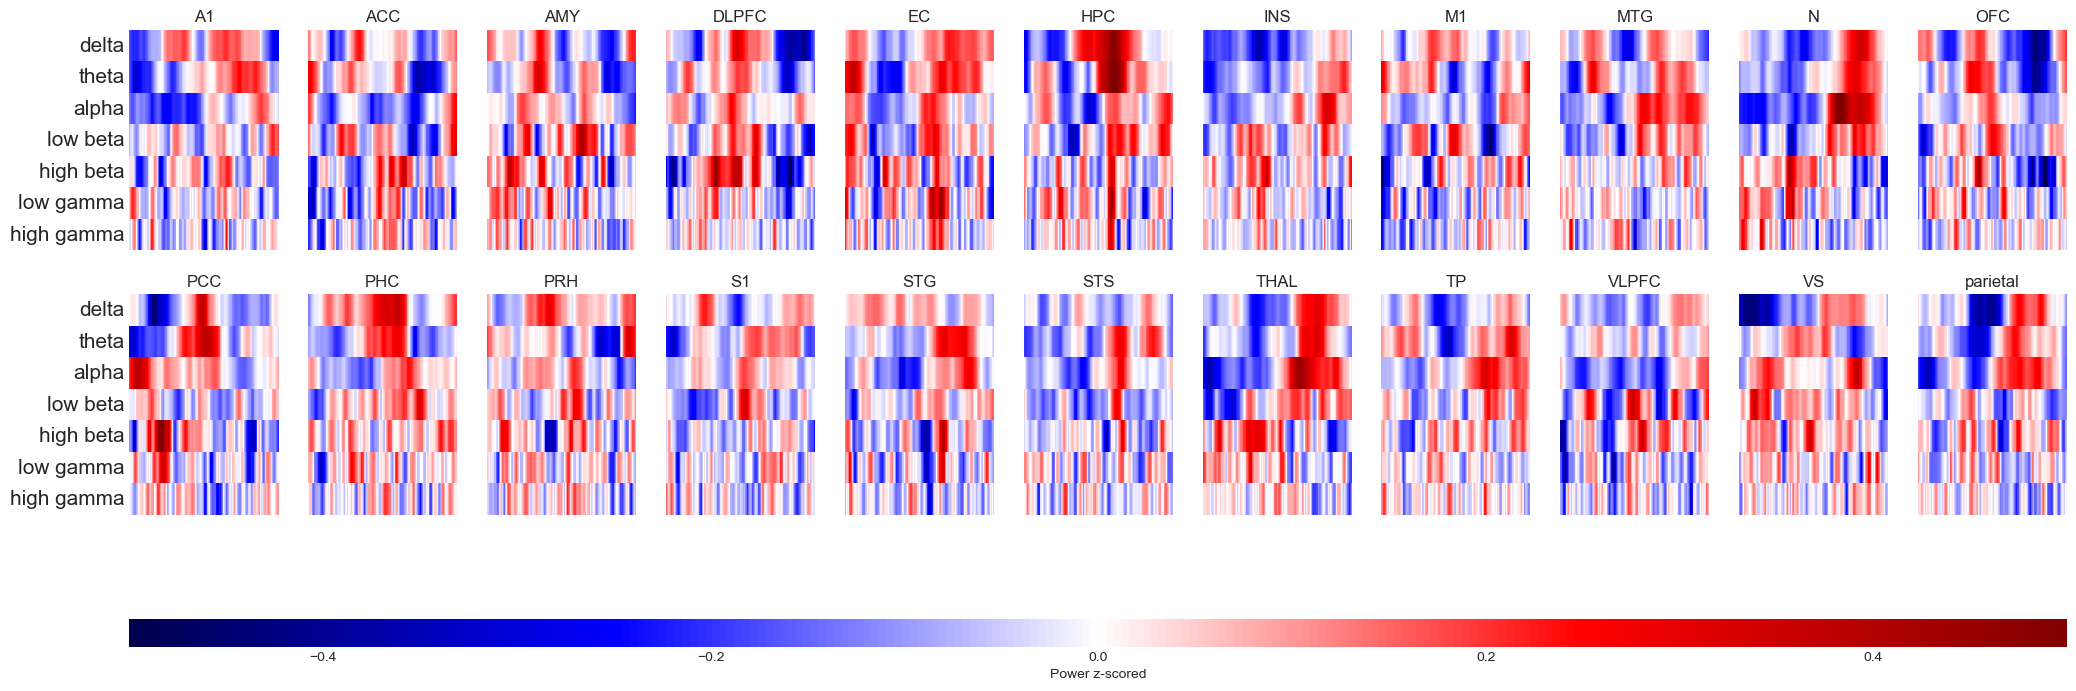

In [45]:
# select each region
hm_list = []
from utils import FREQ_BAND
fig, axs= plt.subplots(2, int(len(np.unique(df.region))/2), figsize = (25, 9), sharey=True)

for r, ax in zip(np.unique(df.region), axs.flatten()) : #['A1']
    id_r = df[df['region'] == r ].index
    tfrm_r = TFRm[0, id_r, :, :].mean(axis=0)
    hm = sns.heatmap(tfrm_r, ax=ax,cbar=False, cmap = 'seismic', vmin = -0.5, vmax = 0.5, xticklabels=False)
    hm_list.append(hm)
    ax.set_title(r)
    ax.grid()
    ax.set_yticklabels([f.replace('_', ' ') for f in FREQ_BAND], rotation = 0, fontsize = 15)
    #ax.invert_yaxis()

cbar = fig.colorbar(hm_list[-1].collections[-1], ax=axs, orientation='horizontal',  aspect=70)
cbar.set_label("Power z-scored")
    

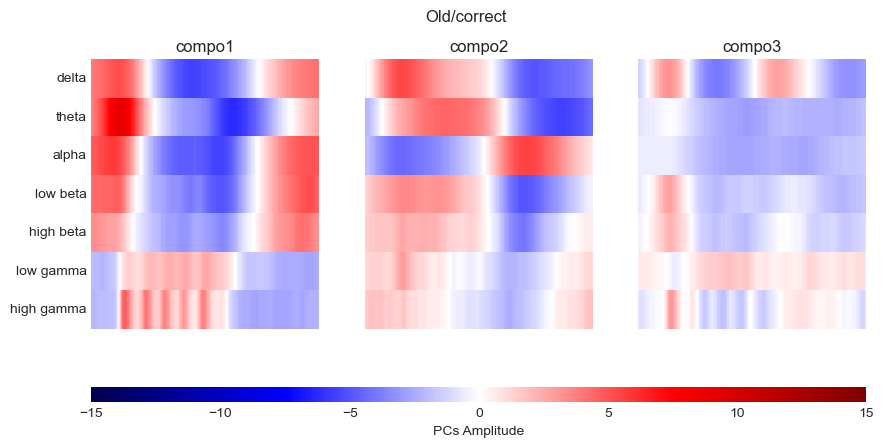

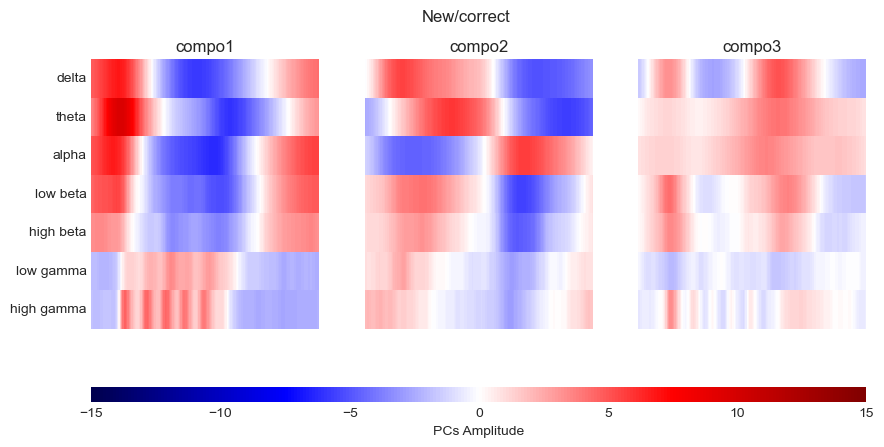

In [30]:
df_pc = pd.read_csv(OUT_PATH + '/grpPCA/supsubj_concat/grp_concat_Xtrans_PCA3.csv').drop(columns = ['Unnamed: 0', 'subj', 'freq', 'expl_var'])
fig, ax= plt.subplots(1, 3, figsize=(10, 5), sharex=True, sharey=True)
fig.suptitle('Old/correct')

for i, pc in enumerate(np.unique(df_pc['compo'])) : 
    df_sub = df_pc[df_pc['compo'] == pc].drop(columns = 'compo').values
    hm = sns.heatmap(df_sub[:,:int(df_sub.shape[1]/2 )], ax=ax[i],cbar=False, cmap = 'seismic', vmin = -15, vmax = 15, xticklabels=False)
    hm_list.append(hm)
    ax[i].set_title(pc)
    ax[i].set_yticklabels([f.replace('_', ' ') for f in FREQ_BAND], rotation = 0)

cbar = fig.colorbar(hm_list[-1].collections[-1], ax=ax, orientation='horizontal',  aspect=50)
cbar.set_label("PCs Amplitude")

fig, ax= plt.subplots(1, 3, figsize=(10, 5), sharex=True, sharey=True)
fig.suptitle('New/correct')
hm_list = []
for i, pc in enumerate(np.unique(df_pc['compo'])) : 
    df_sub = df_pc[df_pc['compo'] == pc].drop(columns = 'compo').values
    hm = sns.heatmap(df_sub[:,int(df_sub.shape[1]/2 ):], ax=ax[i],cbar=False, cmap = 'seismic', vmin = -15, vmax = 15, xticklabels=False)
    hm_list.append(hm)

    ax[i].set_yticklabels([f.replace('_', ' ') for f in FREQ_BAND], rotation = 0)
    ax[i].set_title(pc)
cbar = fig.colorbar(hm_list[-1].collections[-1], ax=ax, orientation='horizontal',  aspect=50)
cbar.set_label("PCs Amplitude")


## PCA PIPLINE PLOT INTRO

### Baseline adjustement

In [13]:
import pickle
event_ids = [1, 2]
baseline_mean_list = {}
mean_trials_baseline_list={}
list_ = {}
for subj in subj_included[:3] : 
    info_file = f'{OUT_PATH}/Data/{subj}_info.json'
    with open(info_file) as f:
        info = json.load(f)
        time = info['time_tfr']
        events_index = np.array([int(i) for i in info['event_id']])

    with open(f'{OUT_PATH}/Data/{subj}_TFRtrials.p', "rb") as f:
        TFRtrials = pickle.load(f)

    TFRm = np.zeros((len(event_ids), TFRtrials.shape[1], TFRtrials.shape[2], TFRtrials.shape[3]))
 
    for i, ev_id in enumerate(event_ids) :
        index_condi = list(np.where(events_index == ev_id)[0])
        TFRm[i, :,:, :] = TFRtrials[np.array(index_condi), :,:,:].mean(0)

    baseline_end = int(time.index([t for t in time if t>=-0.5][0]))
    mean_baseline = TFRm[:, :, 6, :baseline_end].mean(axis=-1, keepdims=True)
    mean_trials_baseline = TFRtrials[:, :, 6,:baseline_end].mean(axis=-1, keepdims=False)
    baseline_mean_list[subj] = mean_baseline[:,:,0]
    mean_trials_baseline_list[subj] = mean_trials_baseline

    # Baseline adjustement 
    TFRm_ad = TFRm[:, :, 6, :] - mean_baseline
    mean_baseline_ad = TFRm_ad[:, :, :baseline_end].mean(axis=-1, keepdims=False)
    list_[subj] = mean_baseline_ad

FileNotFoundError: [Errno 2] No such file or directory: 'outs/Data/LL17_info.json'

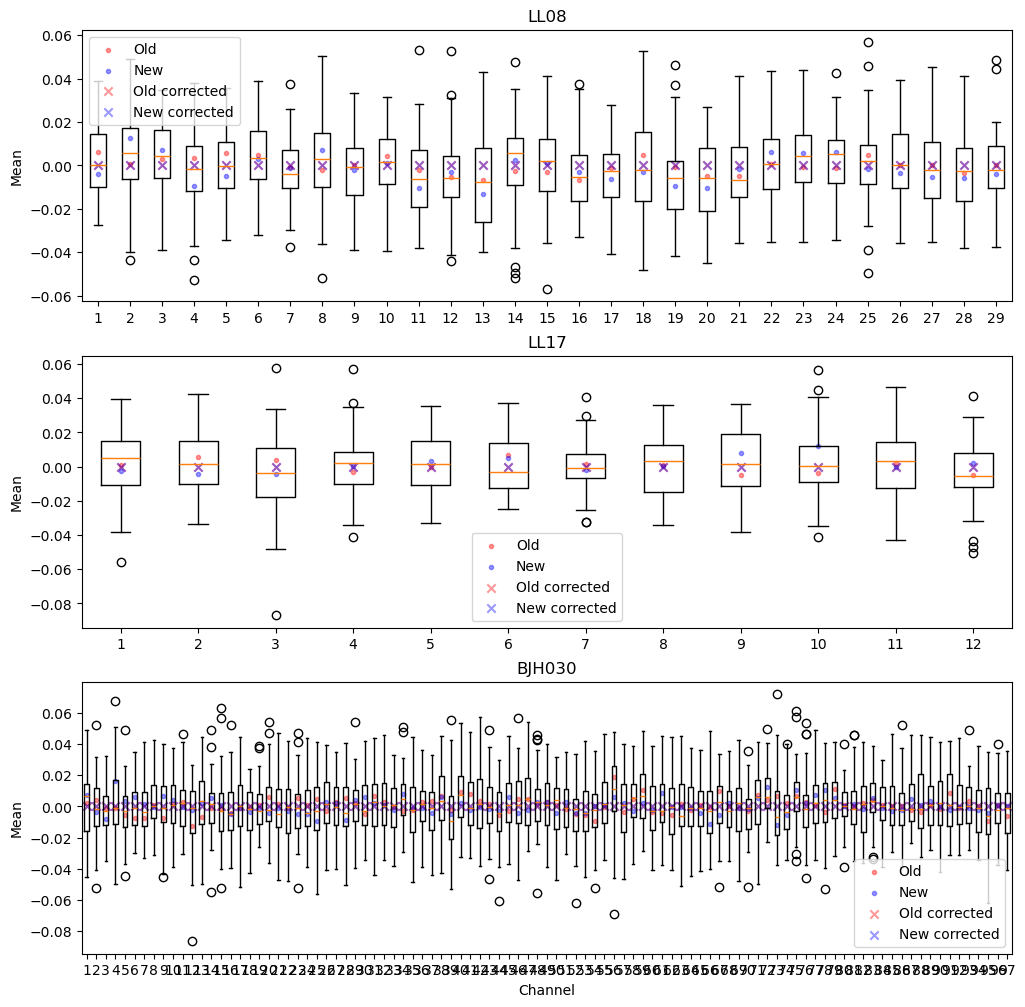

In [ ]:
n_sub = len(mean_trials_baseline_list)
fig, axes = plt.subplots(n_sub, 1, figsize=(12, 4 * n_sub), sharex=False)

for ax, (subj, arr) in zip(axes, mean_trials_baseline_list.items()):
    ax.boxplot([arr[:, ch] for ch in range(arr.shape[1])])
    mean_baseline = baseline_mean_list[subj]
    ax.scatter(np.arange(start = 1, stop =arr.shape[1]+1), mean_baseline[0, :], label='Old', color = 'r', alpha = 0.4,marker='.')
    ax.scatter(np.arange(start=1, stop=arr.shape[1]+1), mean_baseline[1, :], label = 'New', color='b', alpha = 0.4, marker='.')

    ax.scatter(np.arange(start = 1, stop =arr.shape[1]+1), list_[subj][0, :], label='Old corrected', color = 'r', marker='x', alpha = 0.4)
    ax.scatter(np.arange(start=1, stop=arr.shape[1]+1), list_[subj][1, :], label = 'New corrected', color='b', marker='x', alpha = 0.4)
    ax.set_title(subj)
    ax.set_ylabel("Mean")
    ax.legend()
axes[-1].set_xlabel("Channel")
plt.show()

### centering


In [2]:
list_ = []
list_not_adjusted = []
subj_list = []
for subj in subj_included: 
    TFRm = TFRmEvents(subj, data_path=tfr_path)
    # Normalization with baseline  
    with open(tfr_path + f'/{subj}_info.json') as json_data:
        d = json.load(json_data)
        time = d['time_tfr']
        ch_name = d['chnames']
        json_data.close()


    subj_list.extend([subj] * len(ch_name))

    baseline_end = int(time.index([t for t in time if t>0][0]))
    mean_baseline = TFRm[:, :, :, :baseline_end].mean(axis=-1, keepdims=True)
    TFRm_baseline = TFRm-mean_baseline
    list_.append(TFRm_baseline)

list_all = np.concatenate(list_, axis=1)

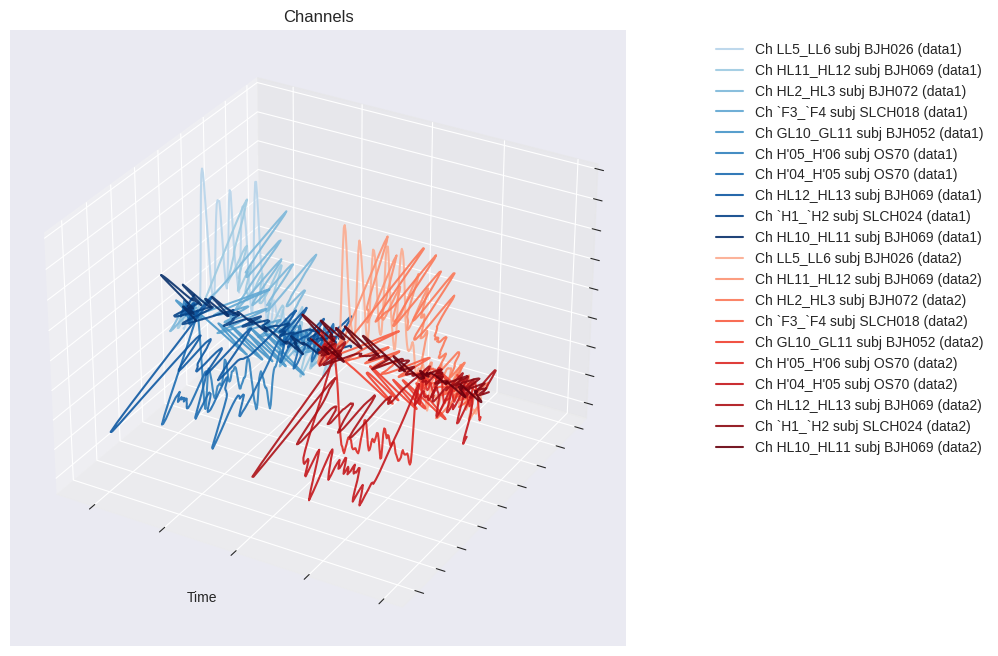

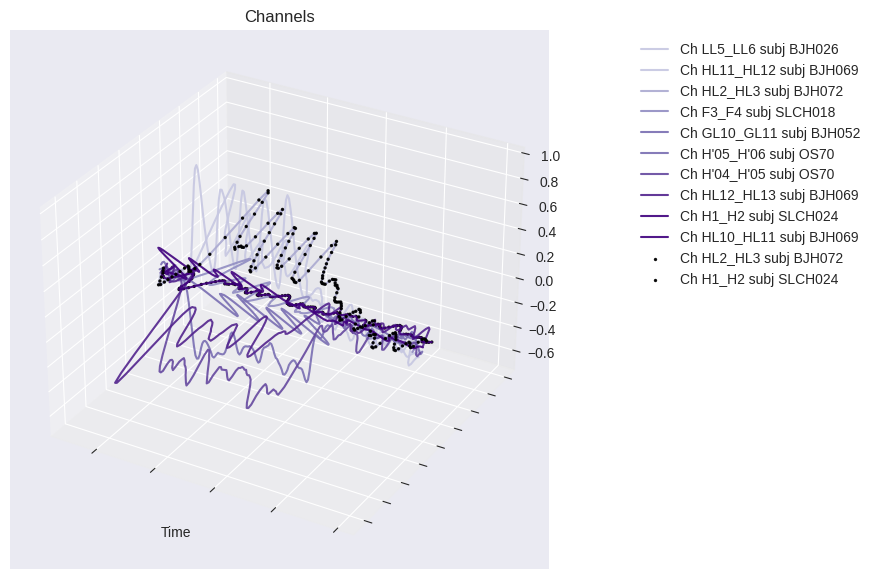

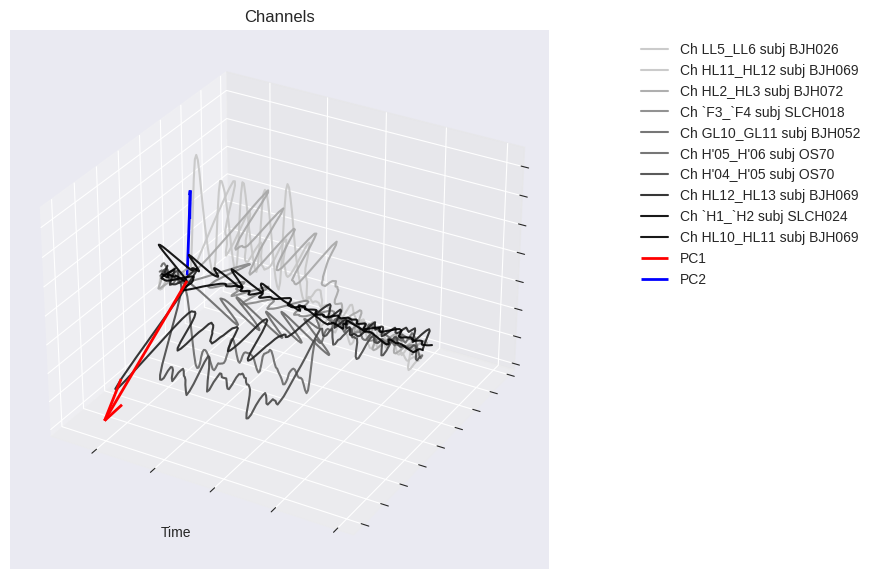

In [3]:
# select a subset of channels
a1 = np.array([a[0] for a in areas])
random.seed(42)
idx_a1 = np.where(a1 == 'A1')[0]
rnd_index_to_pick = random.sample(list(idx_a1), 10)
elects = np.array(elect_list)[rnd_index_to_pick]
subjs = np.array(subj_list)[rnd_index_to_pick]

data1  = list_all[0, rnd_index_to_pick, 6, :]
data2  = list_all[1, rnd_index_to_pick, 6, :]

from utils import PolarChannelSequential, PolarChannel, PolarChannelWithPCA, PolarChannelPloty
concat = np.concat([data1, data2], axis=-1)
PolarChannelSequential(data1, data2, elects=elects, subjs = subjs, data_path = tfr_path)
PolarChannel(list_all[:, rnd_index_to_pick, 6, :].mean(axis=0), elects=elects, subjs = subjs, cmap_name='Purples', to_black=[2, 8], data_path = tfr_path)
datac = list_all[:, :, 6, :].mean(0) - list_all[:, :, 6, :].mean(0).mean(0, keepdims = True)
#PolarChannel(datac[rnd_index_to_pick, :], elects=elects, subjs = subjs, cmap_name='Greens', to_black=[2, 8], data_path = tfr_path)
PolarChannelWithPCA(datac[rnd_index_to_pick, :], elects=elects, subjs = subjs, cmap_name='Greys', data_full = datac, idx_picks=rnd_index_to_pick, data_path = tfr_path)
#PolarChannelPloty(list_all[:, rnd_index_to_pick, 6, :].mean(axis=0), elects=elects, subjs = subjs, data_path = tfr_path)

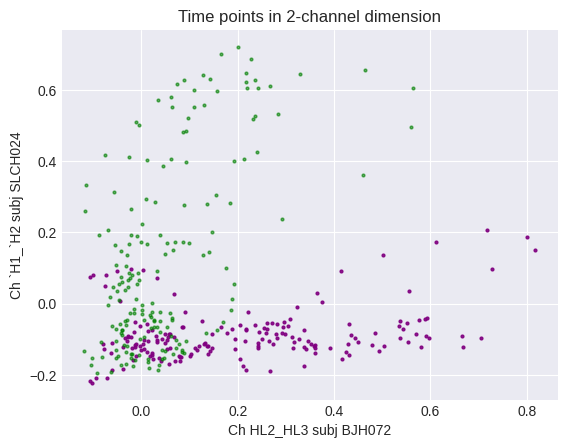

In [4]:
datac = list_all[:, :, 6, :].mean(0) - list_all[:, :, 6, :].mean(0).mean(0, keepdims = True)
data= list_all[:, [rnd_index_to_pick[2], rnd_index_to_pick[8]], 6, :].mean(axis=0)

fig, ax = plt.subplots()
ax.scatter(data[0, :], data[1, :],s=4, label='Not Channel-Centred', color = 'purple', alpha = 0.9)
ax.set_xlabel(f'Ch {elects[2]} subj {subjs[2]}')
ax.set_ylabel(f'Ch {elects[8]} subj {subjs[8]}')
ax.set_title('Time points in 2-channel dimension')

# centering
data_c = datac[rnd_index_to_pick[3:5], :]
ax.scatter(data_c[0, :], data_c[1, :],s=4, color='green', label = 'Channel-Centered', alpha = 0.6)
ax.set_xlabel(f'Ch {elects[2]} subj {subjs[2]}')
ax.set_ylabel(f'Ch {elects[8]} subj {subjs[8]}')
ax.set_title('Time points in 2-channel dimension')
ax.grid()

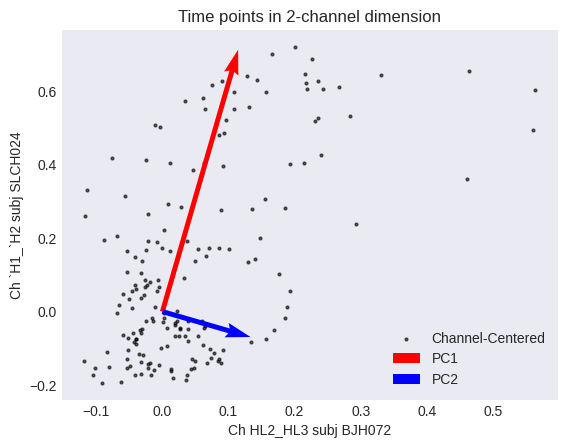

In [5]:
datac = list_all[:, :, 6, :].mean(0) - list_all[:, :, 6, :].mean(0).mean(0, keepdims = True)

data= list_all[:, [rnd_index_to_pick[2], rnd_index_to_pick[8]], 6, :].mean(axis=0)

# centering 
data_c = datac[rnd_index_to_pick[3:5], :]
plt.scatter(data_c[0, :], data_c[1, :], s=4, color='black', label = 'Channel-Centered', alpha = 0.6)
plt.xlabel(f'Ch {elects[2]} subj {subjs[2]}')
plt.ylabel(f'Ch {elects[8]} subj {subjs[8]}')
plt.title('Time points in 2-channel dimension')

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(data_c.T)
components = pca.components_  # shape = (2, 2)
explained_var = pca.explained_variance_  # length 2
scale = 2  # arbitrary scaling for visualization

pc1 = components[0] * np.sqrt(explained_var[0]) * scale
pc2 = components[1] * np.sqrt(explained_var[1]) * scale
origin = np.array([0, 0])  # PCA is computed on centered data
plt.quiver(*origin, pc1[0], pc1[1], color='red', scale=1, width=0.01, label='PC1')
plt.quiver(*origin, pc2[0], pc2[1], color='blue', scale=1, width=0.01, label='PC2')
plt.legend()
